In [1]:
import numpy as np
from sklearn.metrics import roc_curve, auc, f1_score, accuracy_score, classification_report
from itertools import permutations
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.patches import Rectangle
import os
import json

In [2]:
def extract_hard_output(predictions_file):
    y_true = []
    y_pred = []

    with open(predictions_file, "r") as f:
        next(f)

        for line in f:
            line = line.strip()
            if not line:
                continue

            actual, pred = line.split("\t")

            y_true.append(int(actual))
            y_pred.append(int(pred))

    return np.array(y_true), np.array(y_pred)

In [3]:
def extract_soft_output(predictions_file):
    y_true = []
    y_scores = []

    with open(predictions_file, "r") as f:
        next(f)

        for line in f:
            line = line.strip()
            if not line:
                continue

            parts = line.split("\t")
            y_true.append(int(parts[0]))
            y_scores.append([float(s) for s in parts[1].split(",")])

    return np.array(y_true), np.array(y_scores)

In [4]:
def pauc_at_fpr(
    y_true: np.ndarray,
    y_scores: np.ndarray,
    positive_class_idx: int,
    fpr_threshold: float = 0.01,
    normalize: bool = True,
) -> float:
    binary_labels = (y_true != positive_class_idx).astype(int)
    scores = 1.0 - y_scores[:, positive_class_idx]

    fpr, tpr, _ = roc_curve(binary_labels, scores)

    tpr_at_threshold = np.interp(fpr_threshold, fpr, tpr)

    mask = fpr <= fpr_threshold
    fpr_clip = np.concatenate([fpr[mask], [fpr_threshold]])
    tpr_clip = np.concatenate([tpr[mask], [tpr_at_threshold]])

    partial = auc(fpr_clip, tpr_clip)

    return partial / fpr_threshold if normalize else partial, tpr_at_threshold

In [5]:
datasets = [
    'cic-iomt',
    'edge-iiot',
    'iot-nidd'
]

couples = list(permutations(datasets, 2))

In [6]:
models = [
    'hybrid',
    'hybrid_ampe_probs',
    ]

base_exp_folder = f'/home/{os.environ['USER']}/qml-nids/Results/models_outputs'
base_folder = f'{base_exp_folder}/cross_eval'
metrics_dir = f'/home/{os.environ['USER']}/qml-nids/Results/metrics'
output_dir = f'/home/{os.environ['USER']}/qml-nids/Results/plots'

In [7]:
rows = []

dss_benign_idx = {
    'cic-iomt': 1,
    'edge-iiot': 0,
    'iot-nidd': 0,
}

for src, tgt in couples:
    for m in models:
        cross_path = f"{base_folder}/crosseval_src_{src}_tgt_{tgt}/{m}"

        fold_paucs = []
        fold_f1s = []
        fold_tpr = []

        for f in range(1,6):
            fold_path = f"{cross_path}/fold_{f}"

            with open(f'{cross_path}/source_labels_map.json', 'r') as json_file:
                dictionary = json.load(json_file)
            benign_idx = int(next(k for k, v in dictionary.items() if v == 'benign'))

            y_true, y_scores = extract_soft_output(f"{fold_path}/soft_output.dat")
            pauc, tpr_1perc = pauc_at_fpr(y_true, y_scores, positive_class_idx=benign_idx)
            fold_paucs.append(pauc)
            
            y_true, y_pred = extract_hard_output(f"{fold_path}/hard_output.dat")
            y_true_new = np.where(y_true == benign_idx, 'benign', 'malicious')
            y_pred_new = np.where(y_pred == benign_idx, 'benign', 'malicious')

        rows.append({
            "source":    src,
            "target":    tgt,
            "model":     m,
            "avg_pauc":  np.mean(fold_paucs)*100,
            "std_pauc":  np.std(fold_paucs)*100,
        })


In [8]:
base_exp_folder = f'/home/{os.environ['USER']}/qml-nids/Results/models_outputs'

for d in datasets:
    dataset_path = f"{base_exp_folder}/{d}/trained_models"
    for m in models:
        model_path = f"{dataset_path}/100perc/{m}"

        fold_paucs = []
        fold_tpr = []
        fold_f1s = []

        for f in range(1,6):
            fold_path = f"{model_path}/fold_{f}"

            with open(f'{model_path}/labels_map.json', 'r') as json_file:
                dictionary = json.load(json_file)
            benign_idx = int(next(k for k, v in dictionary.items() if v == 'benign'))

            y_true, y_scores = extract_soft_output(f"{fold_path}/soft_output.dat")
            pauc, tpr_1perc = pauc_at_fpr(y_true, y_scores, positive_class_idx=benign_idx)
            fold_paucs.append(pauc)
            fold_tpr.append(tpr_1perc)
            
            y_true, y_pred = extract_hard_output(f"{fold_path}/hard_output.dat")
            y_true_new = np.where(y_true == benign_idx, 'benign', 'malicious')
            y_pred_new = np.where(y_pred == benign_idx, 'benign', 'malicious')
            fold_f1s.append(accuracy_score(y_true_new, y_pred_new)) # f1 -- binary case


        rows.append({
            "source":    d,
            "target":    d,
            "model":     m,
            "avg_pauc":  np.mean(fold_paucs)*100,
            "std_pauc":  np.std(fold_paucs)*100,
        })

In [9]:
df_cross = pd.DataFrame(rows, columns=["source", "target", "model", "avg_pauc", "std_pauc"])
df_cross.to_csv(f'{metrics_dir}/oc2_cross_eval.csv', index=False)
df_cross

,source,target,model,avg_pauc,std_pauc
0,cic-iomt,edge-iiot,hybrid,31.177705,5.250307
1,cic-iomt,edge-iiot,hybrid_ampe_probs,39.177702,4.739997
2,cic-iomt,iot-nidd,hybrid,53.299268,12.179201
3,cic-iomt,iot-nidd,hybrid_ampe_probs,76.310269,6.238108
4,edge-iiot,cic-iomt,hybrid,72.929074,13.077224
5,edge-iiot,cic-iomt,hybrid_ampe_probs,66.869924,10.483554
6,edge-iiot,iot-nidd,hybrid,72.545909,10.828028
7,edge-iiot,iot-nidd,hybrid_ampe_probs,69.830614,23.793252
8,iot-nidd,cic-iomt,hybrid,16.335972,0.637157
9,iot-nidd,cic-iomt,hybrid_ampe_probs,15.584062,1.776002


In [10]:
# Fold-wise results
fold_rows = []

for src, tgt in couples:
    for m in models:
        cross_path = f"{base_folder}/crosseval_src_{src}_tgt_{tgt}/{m}"

        with open(f'{cross_path}/source_labels_map.json', 'r') as json_file:
            dictionary = json.load(json_file)
        benign_idx = int(next(k for k, v in dictionary.items() if v == 'benign'))

        for f in range(1, 6):
            fold_path = f"{cross_path}/fold_{f}"

            y_true, y_scores = extract_soft_output(f"{fold_path}/soft_output.dat")
            pauc, tpr_1perc = pauc_at_fpr(y_true, y_scores, positive_class_idx=benign_idx)

            y_true_h, y_pred_h = extract_hard_output(f"{fold_path}/hard_output.dat")
            y_true_new = np.where(y_true_h == benign_idx, 'benign', 'malicious')
            y_pred_new = np.where(y_pred_h == benign_idx, 'benign', 'malicious')

            fold_rows.append({
                "source": src,
                "target": tgt,
                "model":  m,
                "fold":   f,
                "pauc":    pauc * 100,
            })


In [11]:

for d in datasets:
    dataset_path = f"{base_exp_folder}/{d}/trained_models"
    for m in models:
        model_path = f"{dataset_path}/100perc/{m}"

        fold_paucs = []
        fold_tpr = []
        fold_f1s = []

        for f in range(1,6):
            fold_path = f"{model_path}/fold_{f}"

            with open(f'{model_path}/labels_map.json', 'r') as json_file:
                dictionary = json.load(json_file)
            benign_idx = int(next(k for k, v in dictionary.items() if v == 'benign'))

            y_true, y_scores = extract_soft_output(f"{fold_path}/soft_output.dat")
            pauc, tpr_1perc = pauc_at_fpr(y_true, y_scores, positive_class_idx=benign_idx)
            fold_paucs.append(pauc)
            
            y_true, y_pred = extract_hard_output(f"{fold_path}/hard_output.dat")
            y_true_new = np.where(y_true == benign_idx, 'benign', 'malicious')
            y_pred_new = np.where(y_pred == benign_idx, 'benign', 'malicious')


            fold_rows.append({
                "source":    d,
                "target":    d,
                "model":     m,
                "fold":   f,
                "pauc":   pauc * 100,
            })

In [12]:

df_folds = pd.DataFrame(fold_rows, columns=["source", "target", "model", "fold", "pauc"])
df_folds.to_csv(f'{metrics_dir}/oc2_cross_eval_fold-wise.csv', index=False)
df_folds

,source,target,model,fold,pauc
0,cic-iomt,edge-iiot,hybrid,1,28.848076
1,cic-iomt,edge-iiot,hybrid,2,26.393664
2,cic-iomt,edge-iiot,hybrid,3,35.680126
3,cic-iomt,edge-iiot,hybrid,4,39.034410
4,cic-iomt,edge-iiot,hybrid,5,25.932251
...,...,...,...,...,...
85,iot-nidd,iot-nidd,hybrid_ampe_probs,1,97.487611
86,iot-nidd,iot-nidd,hybrid_ampe_probs,2,95.191769
87,iot-nidd,iot-nidd,hybrid_ampe_probs,3,95.228197
88,iot-nidd,iot-nidd,hybrid_ampe_probs,4,95.537699


In [13]:
model_a, model_b = models[0], models[1]   # 'hybrid' vs 'hybrid_ampe_probs'
metric = "pauc"

pivot = df_folds.pivot_table(
    index=["source", "target", "fold"], columns="model", values=metric
).reset_index()

pivot["winner"] = np.where(
    pivot[model_a] > pivot[model_b], model_a,
    np.where(pivot[model_b] > pivot[model_a], model_b, "tie")
)


summary = (
    pivot.groupby(["source", "target"])["winner"]
    .value_counts()
    .unstack(fill_value=0)
)
summary["total_folds"] = summary[[c for c in [model_a, model_b, "tie"] if c in summary.columns]].sum(axis=1)

for col in [model_a, model_b]:
    if col in summary.columns:
        summary[f"{col}_win_rate"] = summary[col].astype(str) + "/" + summary["total_folds"].astype(str)

summary


winner               hybrid  hybrid_ampe_probs  total_folds hybrid_win_rate  \
source    target                                                              
cic-iomt  cic-iomt        3                  2            5             3/5   
          edge-iiot       1                  4            5             1/5   
          iot-nidd        0                  5            5             0/5   
edge-iiot cic-iomt        3                  2            5             3/5   
          edge-iiot       5                  0            5             5/5   
          iot-nidd        2                  3            5             2/5   
iot-nidd  cic-iomt        4                  1            5             4/5   
          edge-iiot       2                  3            5             2/5   
          iot-nidd        5                  0            5             5/5   

winner              hybrid_ampe_probs_win_rate  
source    target                                
cic-iomt  cic-iomt                         2/5  
          edge-iiot                        4/5  
          iot-nidd                         5/5  
edge-iiot cic-iomt                         2/5  
          edge-iiot                        0/5  
          iot-nidd                         3/5  
iot-nidd  cic-iomt                         1/5  
          edge-iiot                        3/5  
          iot-nidd                         0/5

## Pie charts grid

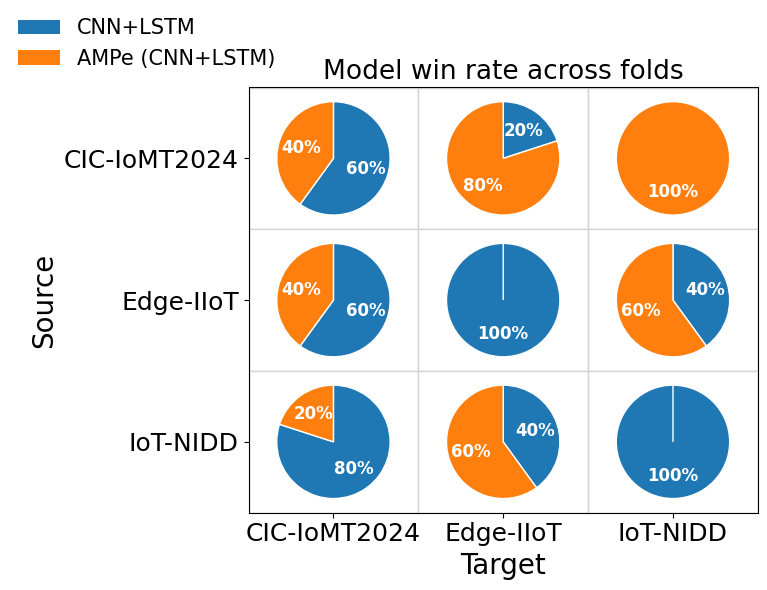

In [ ]:
models = [m for m in [model_a, model_b] if m in summary.columns]
plot_df = summary.copy()

dataset_name_map = {
    'cic-iomt': 'CIC-IoMT2024',
    'edge-iiot': 'Edge-IIoT',
    'iot-nidd': 'IoT-NIDD'
}

model_name_map = {
    'hybrid': 'CNN+LSTM',
    'ampe_fixed_probs': 'AMPe (Dense)',
    'hybrid_ampe_probs': 'AMPe (CNN+LSTM)'
}

for model in models:
    plot_df[f"{model}_pct"] = (
        plot_df[model] / plot_df["total_folds"] * 100
    )

# Stesso ordine per righe e colonne
order = pd.Index(
    list(dict.fromkeys(
        list(plot_df.index.get_level_values("source"))
        + list(plot_df.index.get_level_values("target"))
    ))
)

sources = order
targets = order

source_labels = [
    dataset_name_map.get(s, s)
    for s in sources
]
target_labels = [
    dataset_name_map.get(t, t)
    for t in targets
]
model_labels = [
    model_name_map.get(m, m)
    for m in models
]

fig, ax = plt.subplots(
    figsize=(
        max(8, len(targets) * 2.2),
        max(6, len(sources) * 2.0)
    )
)

ax.set_xlim(0, len(targets))
ax.set_ylim(0, len(sources))
ax.invert_yaxis()

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

model_colors = {
    model: colors[i % len(colors)]
    for i, model in enumerate(models)
}

for i, source in enumerate(sources):
    for j, target in enumerate(targets):

        ax.add_patch(
            patches.Rectangle(
                (j, i),
                1,
                1,
                facecolor="white",
                edgecolor="lightgray",
                linewidth=1
            )
        )

        # Se non esiste il confronto, lascia la cella vuota
        if (source, target) not in plot_df.index:
            continue

        row = plot_df.loc[(source, target)]
        total = row["total_folds"]

        if total == 0:
            continue

        values = [
            row[f"{model}_pct"]
            for model in models
        ]

        pie_ax = ax.inset_axes(
            [
                j + 0.0,   # x
                i + 0.0,   # y
                1.0,       # width
                1.0        # height
            ],
            transform=ax.transData
        )

        pie_ax.pie(
            values,
            colors=[model_colors[m] for m in models],
            startangle=90,
            counterclock=False,
            autopct=lambda pct: f"{pct:.0f}%" if pct > 0 else "",
            textprops={"fontsize": 12, "fontweight": "bold", "color": "white"},
            wedgeprops={
                "edgecolor": "white",
                "linewidth": 1
            }
        )

        pie_ax.set_aspect("equal")
        pie_ax.axis("off")


ax.set_xticks(np.arange(len(targets)) + 0.5)
ax.set_xticklabels(target_labels, fontsize=18)

ax.set_yticks(np.arange(len(sources)) + 0.5)
ax.set_yticklabels(source_labels, fontsize=18)

ax.set_xlabel("Target", fontsize=20)
ax.set_ylabel("Source", fontsize=20)

ax.set_title(
    "Model win rate across folds",
    fontsize=19,
)


legend_handles = [
    patches.Patch(
        facecolor=model_colors[model],
        label=model_labels[i],
    )
    for i,model in enumerate(models)
]

ax.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(-0.2, 1.00),
    ncol=1,
    frameon=False,
    fontsize=15,
)

plt.tight_layout()
plt.show()

## PAUC (Heatmap)

In [15]:
def get_text_color(value):
    """Restituisce bianco o nero in base alla luminanza del colore di sfondo"""
    r, g, b, _ = cmap(norm(value))
    # luminanza percepita (formula standard)
    luminance = 0.299 * r + 0.587 * g + 0.114 * b
    return 'white' if luminance < 0.5 else 'black'

import matplotlib.cm as cm
import matplotlib.colors as mcolors

cmap = cm.get_cmap('YlOrRd')
norm = mcolors.Normalize(vmin=0, vmax=100)

def plot_custom_matrix(df, summary, model_name, metric="pauc", win_threshold=4,
                        thick_linewidth=4.2, thin_linewidth=0.5, rect_color='#006699'):

    df_model = df[df['model'] == model_name]

    dataset_name_map = {
        'cic-iomt': 'IoMT',
        'edge-iiot': 'Edge',
        'iot-nidd': 'NIDD'
    }

    metric_name_map = {
        "f1": "F1-score",
        "pauc": "pAUC",
        "tpr": "TPR",
    }

    pivot_val = df_model.pivot(index='source', columns='target', values=f'avg_{metric}')
    pivot_std = df_model.pivot(index='source', columns='target', values=f'std_{metric}')

    df_summary = summary.reset_index() if not {'source', 'target'}.issubset(summary.columns) else summary.copy()
    pivot_wins = df_summary.pivot(index='source', columns='target', values=model_name)
    pivot_wins = pivot_wins.reindex(index=pivot_val.index, columns=pivot_val.columns)

    pivot_val.rename(index=dataset_name_map, columns=dataset_name_map, inplace=True)

    annot_matrix = np.empty(pivot_val.shape, dtype=object)
    for i in range(pivot_val.shape[0]):
        for j in range(pivot_val.shape[1]):
            val = pivot_val.iloc[i, j]
            std = pivot_std.iloc[i, j]
            if not np.isnan(val):
                annot_matrix[i, j] = f"{val:.2f}\n(±{std:.2f})"
            else:
                annot_matrix[i, j] = ""

    plt.figure(figsize=(8, 5))
    ax = sns.heatmap(
        pivot_val,
        annot=False,
        fmt="",
        cmap='YlOrRd',
        linewidths=0.5,
        vmin=0,
        vmax=100,
        annot_kws={'size': 22, 'weight': 'bold'},
        cbar_kws={'label': 'pAUC [%]'}
    )
    ax.tick_params(axis='x', labelsize=27)
    ax.tick_params(axis='y', labelsize=27)

    for i in range(pivot_val.shape[0]):
        for j in range(pivot_val.shape[1]):
            val = pivot_val.iloc[i, j]
            std = pivot_std.iloc[i, j]
            if not np.isnan(val):
                text_color = get_text_color(val)
                ax.text(j + 0.5, i + 0.42, f"{val:.2f}",
                        ha='center', va='center',
                        fontsize=22, fontweight='bold', color=text_color)
                ax.text(j + 0.5, i + 0.65, f"(±{std:.2f})",
                        ha='center', va='center',
                        fontsize=13, fontweight='bold', color=text_color)

    cbar = ax.collections[0].colorbar
    cbar.set_label(f'{metric_name_map[metric]} [%]', fontsize=30, labelpad=15)
    cbar.ax.tick_params(labelsize=28)
    cbar.set_ticks([0, 25, 50, 75, 100])
    cbar.set_ticklabels(['0', '25', '50', '75', '100'])

    for i in range(pivot_wins.shape[0]):
        for j in range(pivot_wins.shape[1]):
            wins = pivot_wins.iloc[i, j]

            if pd.isna(wins):
                continue

            # Highlight 0/5, 1/5, 4/5 e 5/5
            if wins in [0, 1, 4, 5]:
                ax.add_patch(Rectangle(
                    (j, i), 1, 1,
                    fill=False,
                    edgecolor=rect_color,
                    # edgecolor='black',
                    linewidth=thick_linewidth,
                    linestyle='--',
                    zorder=20,
                    clip_on=False
                ))
            else:
                ax.add_patch(Rectangle(
                    (j, i), 1, 1,
                    fill=False,
                    edgecolor='white',
                    linewidth=thin_linewidth,
                    zorder=10,
                    clip_on=False
                ))

    plt.title('Target Dataset', fontsize=29)
    plt.xlabel('', fontsize=18)
    plt.ylabel('Source Dataset', fontsize=30)
    plt.tight_layout()
    plt.savefig(f'{output_dir}/oc2/cross_eval_{metric}_{model_name}_matrix_dashed.svg', dpi=300, bbox_inches='tight')
    plt.show()


/tmp/ipykernel_7677/3905268384.py:11: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('YlOrRd')


hybrid


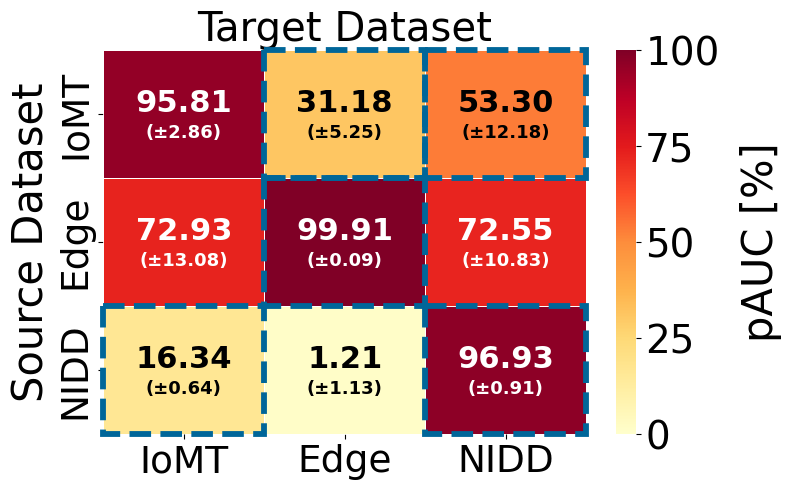

hybrid_ampe_probs


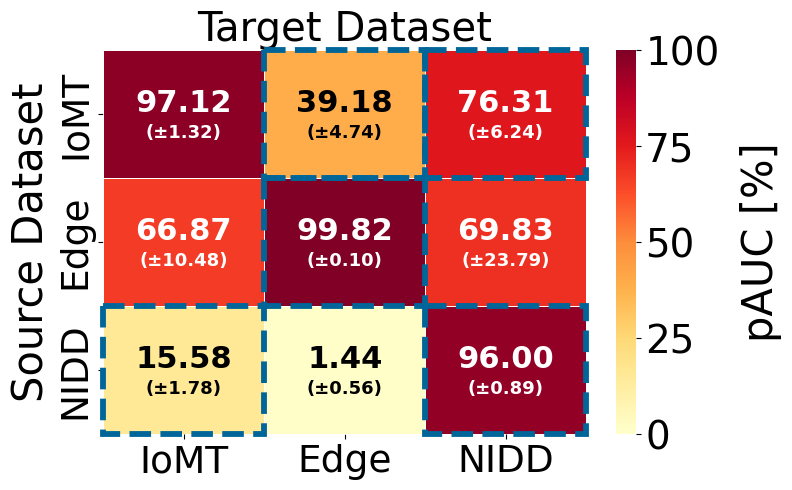

In [16]:

for m in ['hybrid', 'hybrid_ampe_probs']:
    print(m)
    for metric in ['pauc']:
        plot_custom_matrix(df_cross, summary, m, metric=metric, win_threshold=4, rect_color='#006699')